Plots for pulses

In [1]:
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Define variables:
theta = 0
tlist = np.linspace(0, 10, 1500)

#Hilbert space dimension:
N = 2

#Constants:
w = 1
gamma = 1
A = np.linspace(0,np.pi,1000)
t0 = 2
sig = 0.4


#Creatrion/annihilation operator:
sigma = qt.destroy(N)
sigma_dag = sigma.dag()

#Define a dictionary for QuTiP to interpret the time dependence of the gaussian function.
#Gaussian function to model laser pulse: 
def gaussian(t,args):
    
    a = args["a"]
    t0 = args["t0"]
    sig = args["sig"]

    return (a / (np.sqrt(2 * np.pi) * sig)*np.exp(-((t - t0)**2) / (2 * sig**2)))

#Operators:
H0 = w*sigma_dag*sigma
H1 = (sigma + sigma_dag)/2

#Use a nested list so QuTiP evaluates the time dependence itself (cannot use a list of values).
#This is how QuTiP interprets the desired hamiltonian.
Ham = [H0,[H1,gaussian]]

#Collapse operators:
c_ops = [np.sqrt(gamma) * sigma] 


#Ground state:
ground = qt.basis(2,0) * qt.basis(2,0).dag() #Evolved state


rho_list = []
#Initial conditions are still important as the comparison of theta is still needed


x = np.sin(theta)
y = 0
z = np.cos(theta)

rho = 0.5 * (
    qt.qeye(2)
    + x * qt.sigmax()
    + y * qt.sigmay()
    + z * qt.sigmaz())



In [3]:
#Calculate/analyse data:
results = []

#This loops runs throuh each A and then each theta. Ordering A->theta.

for a in A:
    args = {"a": a, "t0": t0, "sig": sig} #Define here so one A value is passed through.
    results.append(qt.mesolve(Ham,rho,tlist,c_ops, args=args, options={"max_step": sig / 10}))#Make step small for small pulses.


all_rho_t = [res.states for res in results] #Gives a list of all rho(t), for different pulse areas.

In [4]:
#Calculate trace distance across all configurations:
Dist = []

for rho_t in all_rho_t: #Loops over A   
    D_t = [qt.tracedist(rho, ground) for rho in rho_t] #Uses pulk p
    Dist.append(D_t)

Dist = np.array(Dist)




#Define list for the maximum Distance index:
max_vals = []
max_vals_index = []
max_vals_time = []
shifted_Dist = []


#Loop over all A values:
for i in range(len(A)):
    max_index = np.argmax(Dist[i]) #Index of max point
    
    max_vals_index.append(max_index)
    max_vals.append(Dist[i][max_index]) #Add max value to list.
    max_vals_time.append(tlist[max_index]) #value of time.
    
    
    #For shifting the peaks in time later:
    #Ignore all before the peak:
    shifted_curve = Dist[i][max_vals_index[i]:]

    shifted_Dist.append(shifted_curve)

    
    
#Detect a cross over: 
#The asympototic parts of the curve dont seem to affect detecting a cross over for this system.

n_a = Dist.shape[0] #Number of theta





#Redefine the cmap matrix, for both quantities:
diff_matrix = np.zeros((n_a, n_a))
time_matrix = np.zeros((n_a, n_a))
strength_matrix = np.zeros((n_a, n_a))

#Calculate the initial difference in distance and time of crossing:
for i in range(n_a):
    for j in range(i + 1, n_a):#Skips repeated pairs of theta.
        
        n = min(len(shifted_Dist[i]), len(shifted_Dist[j])) #May have different distances so n needed.
        
        curve_i = shifted_Dist[i][:n]#Makes both the same length.
        curve_j = shifted_Dist[j][:n]
        
        diff = curve_i - curve_j
        
        diff_0 = diff[0]
        
        diff_matrix[i,j] = diff_0
        diff_matrix[j,i] = diff_0 #Sign doesn't matter, will plot mod as some values may be negative. 
        
        #Time of crossing: 
        crossing_point = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))
        crossing_points = crossing_point[0]#Times where it crossed
        
        if len(crossing_points) > 0:
            first_cross = crossing_points[0]#First cross

            crossing_time = (tlist[max_vals_index[i] + first_cross]
                             - tlist[max_vals_index[i]])#Correct tlist for the start time.

            time_matrix[i,j] = crossing_time
            time_matrix[j,i] = crossing_time #Again, - values shouldn't matter here 
            
            strength = diff_0 / crossing_time
            strength_matrix[i,j] = np.abs(strength)
            strength_matrix[j,i] = np.abs(strength)
            
        else:
            time_matrix[i,j] = 0
            time_matrix[j,i] = 0

            strength_matrix[i,j] = 0
            strength_matrix[j,i] = 0


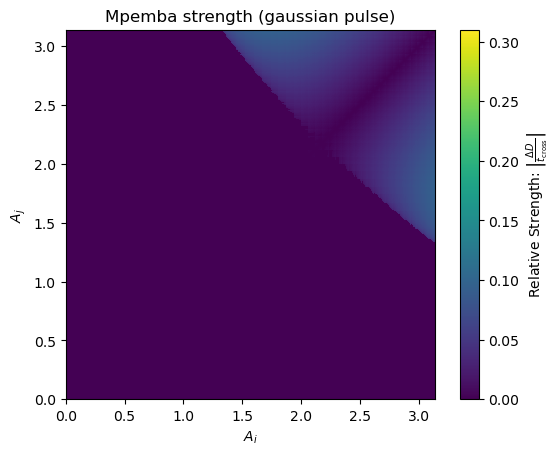

In [5]:
fig4, ax4 = plt.subplots()


image = ax4.imshow(
    strength_matrix,
    origin='lower',
    cmap="viridis",   
    interpolation='nearest',
    extent=[0, np.pi, 0, np.pi],
    vmin=0,
    vmax=0.31)

ax4.set_xlabel(r"$A_{i}$")
ax4.set_ylabel(r"$A_{j}$")
ax4.set_title("Mpemba strength (gaussian pulse)")

fig4.colorbar(image, ax=ax4, label=r"Relative Strength: $\left| \frac{\Delta D}{t_{\mathrm{cross}}} \right|$")

### 